# 1. Aim of the notebook

In this notebook we will select specific regions of interest to apply troutpy on, with the aim of characterizing the nature of transcripts outside segmented regions

## Import packages

In [11]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os 
import numpy as np
import sys

parent_dir = os.path.abspath(os.path.join(os.getcwd(), '../../src/troutpy_reproducibility'))
# Add parent directory to sys.path
sys.path.append(parent_dir)

from roi_processing import *

## Read main path to .zarr file

In [12]:
inpath = "/media/sergio/Meninges/troutpy/raw/Xenium_Prime_Mouse_Brain_Coronal_FF_outs"
sdata = spatialdata_io.xenium(inpath)

output_path = "/media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k"

INFO     reading /media/sergio/Meninges/troutpy/raw/Xenium_Prime_Mouse_Brain_Coronal_FF_outs/cell_feature_matrix.h5


We decide to keep the data in a unified scale (um), which then can be transformated to 'global' coordinates using the according transformation. This global transformation is specially useful for matching the sales of transcripts with ie images

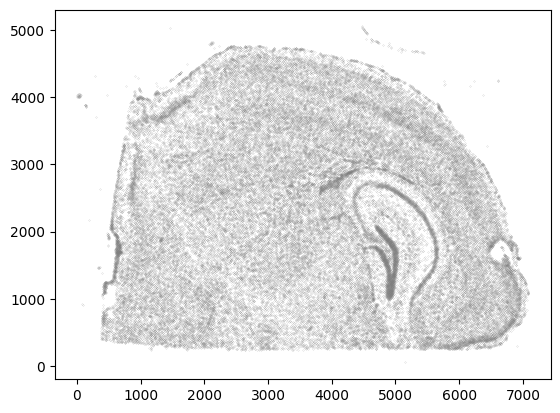

In [13]:
# Visualize using global coordinates
local_coords = sdata['table'].obsm['spatial']
# In case it's needed, chec transformations
#print(  get_transformation(sdata["nucleus_boundaries"]))
spat=[g[0] for g in sdata['table'].obsm['spatial']]
spat2=[g[1] for g in sdata['table'].obsm['spatial']]
plt.scatter(spat,spat2,s=0.01,c='grey')

In [14]:
# ROI selection
bb_xmin =18150 # mix x 
bb_ymin= 2600 #min y
bb_xmax=35199 # max x
bb_ymax=13899.9 # max y

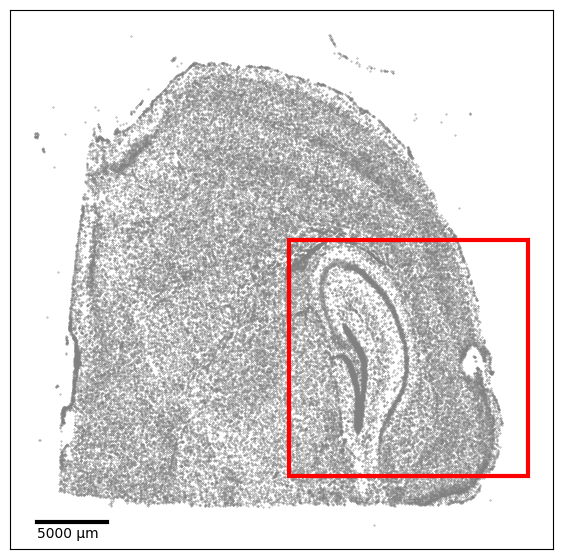

In [15]:
plot_spatial_with_box_and_scale(
    spatial_coords=sdata['table'].obsm['spatial'],
    bb_xmin=bb_xmin,
    bb_xmax=bb_xmax,
    bb_ymin=bb_ymin,
    bb_ymax=bb_ymax
)


Next, we select the ROI of interest

In [16]:
cropped_sdata = sdata.query.bounding_box(
    axes=["x", "y"],min_coordinate=[bb_xmin, bb_ymin],
    max_coordinate=[bb_xmax, bb_ymax],target_coordinate_system="global")

# Save metadata
metadata = generate_metadata(sdata=cropped_sdata,
    sample_id="mouse_brain_5k",
    species="Mus musculus",technology="Xenium",
    segmentation_method="multimodal",roi_name="cortex_ROI_2",
    tissue="brain",disease="control")

rechunk_sdata(cropped_sdata)


Processing image: morphology_focus
  Rechunking scale: scale0
  Applying chunking...
  Rechunking scale: scale1
  Applying chunking...
  Rechunking scale: scale2
  Applying chunking...
  Rechunking scale: scale3
  Applying chunking...
  Rechunking scale: scale4
  Applying chunking...
Processing label: nucleus_labels
  Rechunking scale: scale0
  Applying chunking...
  Rechunking scale: scale1
  Applying chunking...
  Rechunking scale: scale2
  Applying chunking...
  Rechunking scale: scale3
  Applying chunking...
  Rechunking scale: scale4
  Applying chunking...
Processing label: cell_labels
  Rechunking scale: scale0
  Applying chunking...
  Rechunking scale: scale1
  Applying chunking...
  Rechunking scale: scale2
  Applying chunking...
  Rechunking scale: scale3
  Applying chunking...
  Rechunking scale: scale4
  Applying chunking...


In [17]:
# troutpy converter to xenium
troutpy.pp.xenium_converter(cropped_sdata,unassigned_tag='UNASSIGNED')

In [18]:
# Define output paths
zarr_path = os.path.join(output_path,"data.zarr")
metadata_path = os.path.join(output_path,"metadata.csv")

cropped_sdata.write(zarr_path,overwrite=True)
metadata.to_csv(metadata_path, index=False)

INFO     The Zarr backing store has been changed from None the new file path:                                      
         /media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data.zarr                                           
